In [1]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pandas sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine, URL

connection_url = URL.create(
    drivername="mysql+mysqlconnector",
    username="root",
    password="Mysql@0504",
    host="localhost",
    port=3306,
    database="capstone"
)
engine = create_engine(connection_url)

In [2]:
with engine.connect()as connection:
    print("MYSQL connection succesfull!")

MYSQL connection succesfull!


task 1 Load Data from SQL

In [3]:
orders=pd.read_sql("select*from orders",engine)
orders.head(5)

,ORDER_ID,CUSTOMER_ID,ORDER_STATUS,ORDER_DATE,REQUIRED_DATE,SHIPPED_DATE,STORED_ID,STAFF_ID,ORDER_STATUS_[0],MyUnknownColumn,MyUnknownColumn_[0]
0,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,Delivered,,
1,2,1212,4,2016-01-01,2016-01-04,2016-01-03,2,6,Delivered,,
2,3,523,4,2016-01-02,2016-01-05,2016-01-03,2,7,Delivered,,
3,4,175,4,2016-01-03,2016-01-04,2016-01-05,1,3,Delivered,,4 - DELIVERED
4,5,1324,4,2016-01-03,2016-01-06,2016-01-06,2,6,Delivered,,3 - SHIPPED


In [4]:
order_items=pd.read_sql("select*from order_items",engine)
order_items.head(5)

,ORDER_ID,ITEM_ID,PRODUCT_ID,QUANTITY,LIST_PRICE,DISCOUNT,TOTAL_PRICE,PRODUCT_NAME
0,1,1,20,1,599.99,0.20,599.79,Trek 820 - 2016
1,1,2,8,2,1799.99,0.07,3599.91,Ritchey Timberwolf Frameset - 2016
2,1,3,10,2,1549.00,0.05,3097.95,Surly Wednesday Frameset - 2016
3,1,4,16,2,599.99,0.05,1199.93,Trek Fuel EX 8 29 - 2016
4,1,5,4,1,2899.99,0.20,2899.79,Heller Shagamaw Frame - 2016


In [5]:
customers=pd.read_sql("select*from customers",engine)
customers.head(5)

,CUSTOMER_ID,FIRST_NAME,LAST_NAME,PHONE,EMAIL,STREET,CITY,STATE,ZIP CODE
0,1,Debra,Burks,NA,debra.burks@yahoo.com,9273 Thorne Ave.,Orchard Park,NY,14127
1,2,Kasha,Todd,NA,kasha.todd@yahoo.com,910 Vine Street,Campbell,CA,95008
2,3,Tameka,Fisher,NA,tameka.fisher@aol.com,769C Honey Creek St.,Redondo Beach,CA,90278
3,4,Daryl,Spence,NA,daryl.spence@aol.com,988 Pearl Lane,Uniondale,NY,11553
4,5,Charolette,Rice,(916) 381-6003,charolette.rice@msn.com,107 River Dr.,Sacramento,CA,95820


In [6]:
import pandas as pd
products=pd.read_sql("select*from products",engine)
products.head(5)

,PRODUCT_ID,PRODUCT_NAME,BRAND_ID,CATEGORY_ID,MODEL_YEAR,LIST_PRICE
0,1,Trek 820 - 2016,9,6,2016,379.99
1,2,Ritchey Timberwolf Frameset - 2016,5,6,2016,749.99
2,3,Surly Wednesday Frameset - 2016,8,6,2016,999.99
3,4,Trek Fuel EX 8 29 - 2016,9,6,2016,2899.99
4,5,Heller Shagamaw Frame - 2016,3,6,2016,1320.99


task 2 (A) Basic EDA (Exploratory Data Analysis)

In [7]:
## orders table
print("orders info:\n",orders.info())

<class 'pandas.DataFrame'>
RangeIndex: 1615 entries, 0 to 1614
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ORDER_ID             1615 non-null   int64
 1   CUSTOMER_ID          1615 non-null   int64
 2   ORDER_STATUS         1615 non-null   int64
 3   ORDER_DATE           1615 non-null   str  
 4   REQUIRED_DATE        1615 non-null   str  
 5   SHIPPED_DATE         1615 non-null   str  
 6   STORED_ID            1615 non-null   int64
 7   STAFF_ID             1615 non-null   int64
 8   ORDER_STATUS_[0]     1615 non-null   str  
 9   MyUnknownColumn      1615 non-null   str  
 10  MyUnknownColumn_[0]  1615 non-null   str  
dtypes: int64(5), str(6)
memory usage: 138.9 KB
orders info:
 None


In [9]:
print("describe orders :\n",orders.describe())
print("null orders :\n",orders.isnull().sum())
print("duplicated orders:\n",orders.duplicated())
print("value counts:\n",orders["ORDER_STATUS_[0]"].value_counts())

describe orders :
           ORDER_ID  CUSTOMER_ID  ORDER_STATUS    STORED_ID     STAFF_ID
count  1615.000000  1615.000000   1615.000000  1615.000000  1615.000000
mean    808.000000   654.171517      3.778947     1.892260     5.855108
std     466.354658   443.229967      0.693430     0.558395     1.913899
min       1.000000     1.000000      1.000000     1.000000     2.000000
25%     404.500000   237.000000      4.000000     2.000000     6.000000
50%     808.000000   638.000000      4.000000     2.000000     6.000000
75%    1211.500000  1041.500000      4.000000     2.000000     7.000000
max    1615.000000  1445.000000      4.000000     3.000000     9.000000
null orders :
 ORDER_ID               0
CUSTOMER_ID            0
ORDER_STATUS           0
ORDER_DATE             0
REQUIRED_DATE          0
SHIPPED_DATE           0
STORED_ID              0
STAFF_ID               0
ORDER_STATUS_[0]       0
MyUnknownColumn        0
MyUnknownColumn_[0]    0
dtype: int64
duplicated orders:
 0       Fa

task 2 (b) 

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

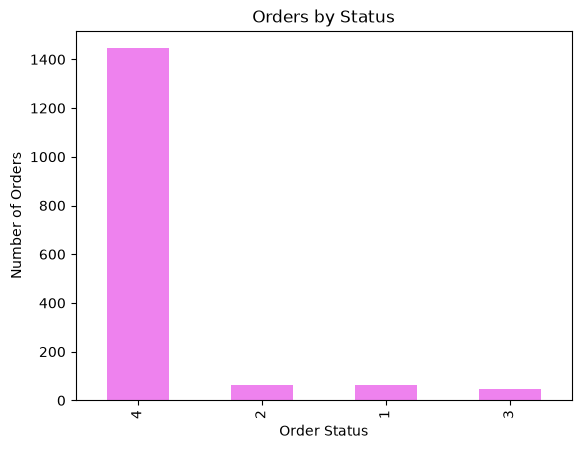

In [11]:
## bar chart
import matplotlib.pyplot as plt

orders['ORDER_STATUS'].value_counts().plot(
    kind='bar',
    color='violet'
)

plt.title('Orders by Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.show()

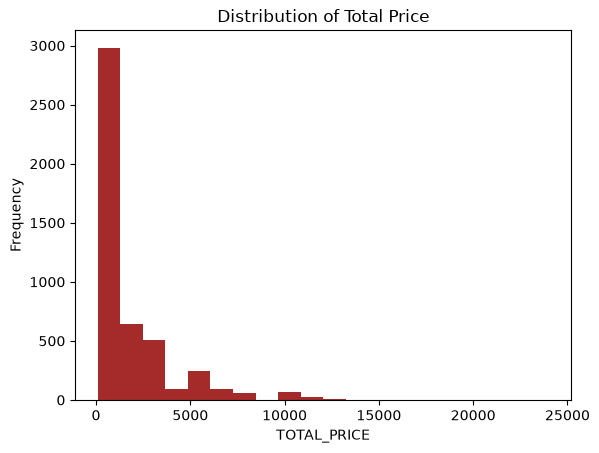

In [12]:
## HISTOGRAM
order_items['TOTAL_PRICE'].plot(kind='hist',  color='brown',bins=20)

plt.title('Distribution of Total Price')
plt.xlabel('TOTAL_PRICE')
plt.ylabel('Frequency')
plt.show()

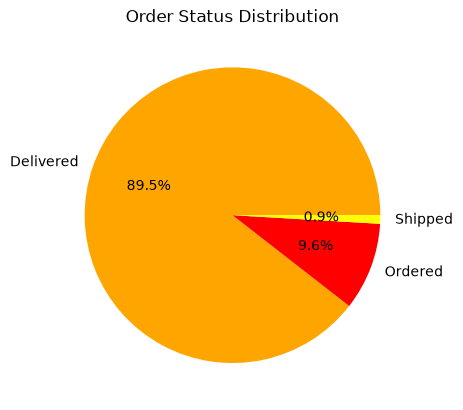

In [13]:
## pie chart
orders['ORDER_STATUS_[0]'].value_counts().plot(
    kind='pie',
     colors=['orange','red','yellow'],
    autopct='%1.1f%%'
)

plt.title('Order Status Distribution')
plt.ylabel('')
plt.show()

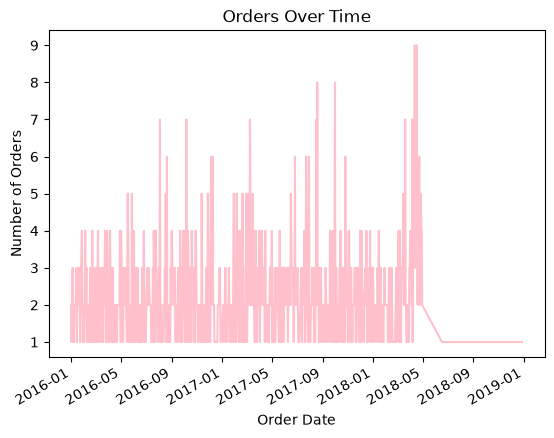

In [14]:
## line chart 
orders['ORDER_DATE'] = pd.to_datetime(orders['ORDER_DATE'])

orders.groupby('ORDER_DATE').size().plot(kind='line', color='pink')

plt.title('Orders Over Time')
plt.xlabel('Order Date')
plt.ylabel('Number of Orders')
plt.show()

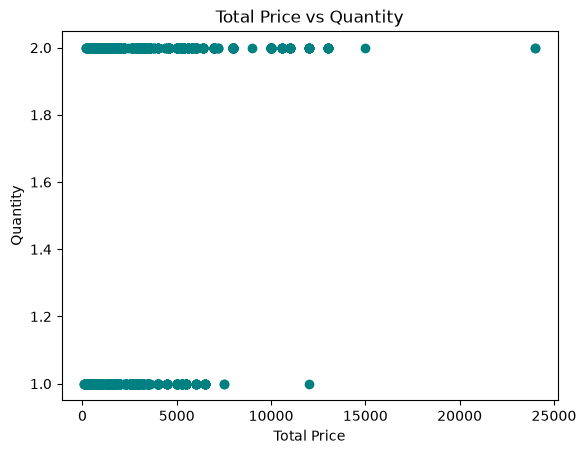

In [15]:
## SCATER CHART

plt.scatter(order_items['TOTAL_PRICE'], order_items['QUANTITY'], color='teal')

plt.title('Total Price vs Quantity')
plt.xlabel('Total Price')
plt.ylabel('Quantity')
plt.show()

In [16]:
print(orders.columns.tolist())

['ORDER_ID', 'CUSTOMER_ID', 'ORDER_STATUS', 'ORDER_DATE', 'REQUIRED_DATE', 'SHIPPED_DATE', 'STORED_ID', 'STAFF_ID', 'ORDER_STATUS_[0]', 'MyUnknownColumn', 'MyUnknownColumn_[0]']


In [17]:
order_items['TOTAL_PRICE'] = (
    order_items['LIST_PRICE'] * order_items['QUANTITY']
) - order_items['DISCOUNT']

In [18]:
orders_rfm = orders.merge(
    order_items[['ORDER_ID', 'TOTAL_PRICE']],
    on='ORDER_ID',
    how='left'
)

In [19]:
orders_rfm['ORDER_DATE'] = pd.to_datetime(orders_rfm['ORDER_DATE'])

reference_date = orders_rfm['ORDER_DATE'].max() + pd.Timedelta(days=1)

rfm = orders_rfm.groupby('CUSTOMER_ID').agg(
    Recency=('ORDER_DATE', lambda x: (reference_date - x.max()).days),
    Frequency=('ORDER_ID', 'nunique'),
    Monetary=('TOTAL_PRICE', 'sum')
).reset_index()

print(rfm.head())

   CUSTOMER_ID  Recency  Frequency  Monetary
0            1       41          3  30644.78
1            2      264          3  21652.87
2            3       69          3  26248.66
3            4      255          3  24197.81
4            5      256          3  19442.01


In [29]:
def segment(row):
    if row["Recency"] <= 520 and row["Frequency"] >= 3 and row["Monetary"] >= 43:
        return "Champions"

    elif row["Recency"] <= 450 and row["Frequency"] >= 2:
        return "Loyal Customers"

    elif row["Recency"] > 459:
        return "At Risk"

    else:
        return "Regular Customer"

In [30]:
rfm["Segment"] = rfm.apply(segment, axis=1)

In [31]:
rfm.head(100)

,CUSTOMER_ID,Recency,Frequency,Monetary,Segment
0,1,41,3,30644.78,Champions
1,2,264,3,21652.87,Champions
2,3,69,3,26248.66,Champions
3,4,255,3,24197.81,Champions
4,5,256,3,19442.01,Champions
...,...,...,...,...,...
95,96,749,1,9097.71,At Risk
96,97,262,2,6899.78,Loyal Customers
97,98,980,1,3079.51,At Risk
98,99,993,1,6290.34,At Risk


In [32]:
rfm.head(100)

,CUSTOMER_ID,Recency,Frequency,Monetary,Segment
0,1,41,3,30644.78,Champions
1,2,264,3,21652.87,Champions
2,3,69,3,26248.66,Champions
3,4,255,3,24197.81,Champions
4,5,256,3,19442.01,Champions
...,...,...,...,...,...
95,96,749,1,9097.71,At Risk
96,97,262,2,6899.78,Loyal Customers
97,98,980,1,3079.51,At Risk
98,99,993,1,6290.34,At Risk


In [33]:
segment_count = rfm['Segment'].value_counts().reset_index()

segment_count.columns = ['Segment', 'Customer_Count']

print(segment_count)

            Segment  Customer_Count
0           At Risk            1021
1  Regular Customer             295
2   Loyal Customers              90
3         Champions              39


In [34]:
rfm.to_sql(
"customer_segments",
con=engine,
if_exists="replace",
index=False
)

1445

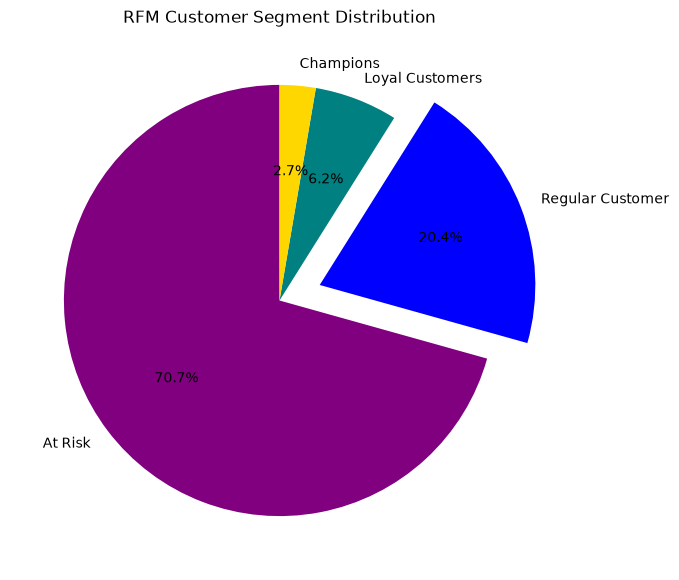

In [26]:
segment_count = rfm['Segment'].value_counts()
colors = ['purple','blue','teal','gold']
explode=[0,0.2,0,0,] 
plt.figure(figsize=(7,7))
plt.pie(segment_count,explode=explode,labels=segment_count.index,autopct='%1.1f%%',startangle=90,colors=colors)
plt.title('RFM Customer Segment Distribution')
plt.show()

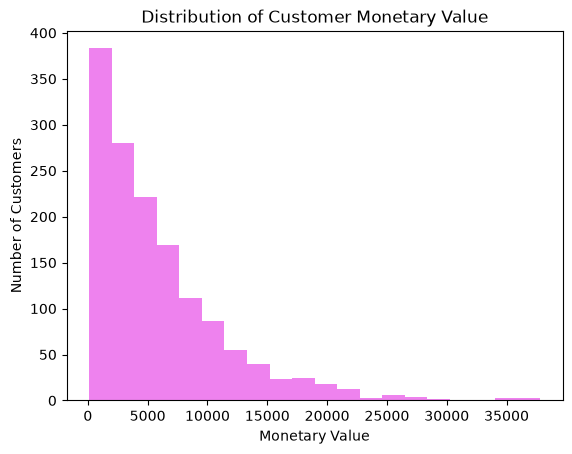

In [27]:
import matplotlib.pyplot as plt

plt.hist(rfm['Monetary'], color='violet',bins=20)

plt.xlabel('Monetary Value')
plt.ylabel('Number of Customers')
plt.title('Distribution of Customer Monetary Value')
plt.show()